# CS232 Final Project
## NYC Taxi Trips

### Requirements

In [32]:
!python -m pip install python-dotenv

Defaulting to user installation because normal site-packages is not writeable


In [2]:
!jupyter nbextension enable --py widgetsnbextension
!jupyter nbextension enable --py gmaps

Enabling notebook extension jupyter-js-widgets/extension...
      - Validating: ok
Enabling notebook extension jupyter-gmaps/extension...
      - Validating: ok


### Import module and check gmap module operation.

For the API key, fill in the MAP_API_KEY variable in the .env file in the same folder.

In [3]:
import os
from dotenv import load_dotenv
import gmaps
from IPython.display import display
import pandas as pd
from matplotlib import pyplot as plt
from datetime import datetime, time
import matplotlib.dates as mdates

BackgroundColor = "#ECE7DC"

In [4]:
load_dotenv(verbose=True)

MAP_API_KEY = os.getenv("MAP_API_KEY")

gmaps.configure(api_key=MAP_API_KEY)
fig = gmaps.figure(map_type='SATELLITE', center = (37.238,127.064),zoom_level=18)
display(fig)

Figure(layout=FigureLayout(height='420px'))

Load trip data files

In [5]:
tripdata_df = pd.read_csv("trip_data/trip_data_1.csv", skipinitialspace=True)
tripdata_df.head()

,medallion,hack_license,vendor_id,rate_code,store_and_fwd_flag,pickup_datetime,dropoff_datetime,passenger_count,trip_time_in_secs,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0,89D227B655E5C82AECF13C3F540D4CF4,BA96DE419E711691B9445D6A6307C170,CMT,1,N,2013-01-01 15:11:48,2013-01-01 15:18:10,4,382,1.0,-73.978165,40.757977,-73.989838,40.751171
1,0BD7C8F5BA12B88E0B67BED28BEA73D8,9FD8F69F0804BDB5549F40E9DA1BE472,CMT,1,N,2013-01-06 00:18:35,2013-01-06 00:22:54,1,259,1.5,-74.006683,40.731781,-73.994499,40.750660
2,0BD7C8F5BA12B88E0B67BED28BEA73D8,9FD8F69F0804BDB5549F40E9DA1BE472,CMT,1,N,2013-01-05 18:49:41,2013-01-05 18:54:23,1,282,1.1,-74.004707,40.737770,-74.009834,40.726002
3,DFD2202EE08F7A8DC9A57B02ACB81FE2,51EE87E3205C985EF8431D850C786310,CMT,1,N,2013-01-07 23:54:15,2013-01-07 23:58:20,2,244,0.7,-73.974602,40.759945,-73.984734,40.759388
4,DFD2202EE08F7A8DC9A57B02ACB81FE2,51EE87E3205C985EF8431D850C786310,CMT,1,N,2013-01-07 23:25:03,2013-01-07 23:34:24,1,560,2.1,-73.976250,40.748528,-74.002586,40.747868


In [6]:
tripFare_df = pd.read_csv("trip_fare/trip_fare_1.csv", skipinitialspace=True)
tripFare_df.head()

,medallion,hack_license,vendor_id,pickup_datetime,payment_type,fare_amount,surcharge,mta_tax,tip_amount,tolls_amount,total_amount
0,89D227B655E5C82AECF13C3F540D4CF4,BA96DE419E711691B9445D6A6307C170,CMT,2013-01-01 15:11:48,CSH,6.5,0.0,0.5,0.0,0.0,7.0
1,0BD7C8F5BA12B88E0B67BED28BEA73D8,9FD8F69F0804BDB5549F40E9DA1BE472,CMT,2013-01-06 00:18:35,CSH,6.0,0.5,0.5,0.0,0.0,7.0
2,0BD7C8F5BA12B88E0B67BED28BEA73D8,9FD8F69F0804BDB5549F40E9DA1BE472,CMT,2013-01-05 18:49:41,CSH,5.5,1.0,0.5,0.0,0.0,7.0
3,DFD2202EE08F7A8DC9A57B02ACB81FE2,51EE87E3205C985EF8431D850C786310,CMT,2013-01-07 23:54:15,CSH,5.0,0.5,0.5,0.0,0.0,6.0
4,DFD2202EE08F7A8DC9A57B02ACB81FE2,51EE87E3205C985EF8431D850C786310,CMT,2013-01-07 23:25:03,CSH,9.5,0.5,0.5,0.0,0.0,10.5


Checking information of dataframes

In [7]:
print(tripdata_df.info())
print(tripFare_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14776615 entries, 0 to 14776614
Data columns (total 14 columns):
 #   Column              Dtype  
---  ------              -----  
 0   medallion           object 
 1   hack_license        object 
 2   vendor_id           object 
 3   rate_code           int64  
 4   store_and_fwd_flag  object 
 5   pickup_datetime     object 
 6   dropoff_datetime    object 
 7   passenger_count     int64  
 8   trip_time_in_secs   int64  
 9   trip_distance       float64
 10  pickup_longitude    float64
 11  pickup_latitude     float64
 12  dropoff_longitude   float64
 13  dropoff_latitude    float64
dtypes: float64(5), int64(3), object(6)
memory usage: 1.5+ GB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14776615 entries, 0 to 14776614
Data columns (total 11 columns):
 #   Column           Dtype  
---  ------           -----  
 0   medallion        object 
 1   hack_license     object 
 2   vendor_id        object 
 3   pickup_datetime  obj

Change the type of datetime items to datetime for the implementation of the code below.

In [8]:
tripdata_df["dropoff_datetime"] = pd.to_datetime(tripdata_df["dropoff_datetime"])
tripdata_df["pickup_datetime"] = pd.to_datetime(tripdata_df["pickup_datetime"])
tripFare_df["pickup_datetime"] = pd.to_datetime(tripFare_df["pickup_datetime"])

I'm trying to use gmap to draw a heatmap on the map to see where people mainly get off.

In [9]:
locations = tripdata_df[["dropoff_longitude", "dropoff_latitude"]][
    (-75 < tripdata_df["dropoff_longitude"]) & (tripdata_df["dropoff_longitude"] < -73) &
    (40 < tripdata_df["dropoff_latitude"]) & (tripdata_df["dropoff_latitude"] < 41) &
    (tripdata_df["dropoff_longitude"] != 0) & (tripdata_df["dropoff_latitude"] != 0)
    ].sample(500000) # Delete anomalies



locations.columns = ["longtitude", "latitude"]
locations = locations.iloc[:, [1, 0]]
locations.describe()

,latitude,longtitude
count,500000.000000,500000.000000
mean,40.751465,-73.974875
std,0.030210,0.033240
min,40.150002,-74.697922
25%,40.736091,-73.991379
50%,40.754215,-73.980560
75%,40.768379,-73.965485
max,40.999371,-73.050003


In [10]:
fig = gmaps.figure(map_type='HYBRID')
heatmap_layer = gmaps.heatmap_layer(locations)
fig.add_layer(heatmap_layer)
display(fig)

Figure(layout=FigureLayout(height='420px'))

The areas where people got off were quite evenly distributed, so I thought that metropolises were different after all. If I had to pick a notable place, 7th Ave and 8th Ave surrounding Madison Square Garden were shown to have a lot more people getting off than other places.

This time, I will merge the two dataframes and check the correlation between the number columns.

In [11]:
tripMerge_df = pd.merge(tripFare_df, tripdata_df[["medallion", "pickup_datetime", "dropoff_datetime", "passenger_count", "trip_time_in_secs", "trip_distance"]], how="left", on=["medallion", "pickup_datetime"])
display(tripMerge_df.sample(5))


,medallion,hack_license,vendor_id,pickup_datetime,payment_type,fare_amount,surcharge,mta_tax,tip_amount,tolls_amount,total_amount,dropoff_datetime,passenger_count,trip_time_in_secs,trip_distance
1619310,41EB334B141D7C05D15BF9FC78540415,3158E46011E95D376541A461895A7730,VTS,2013-01-04 14:17:00,CRD,12.5,0.0,0.5,1.2,0.0,14.2,2013-01-04 14:30:00,1,780,2.96
12255231,787E5ACB6D5685160239D4D45DB509C5,C3A0EB6A6FF531D2C6DC20F3F56414C0,VTS,2013-01-08 02:08:00,CSH,9.0,0.5,0.5,0.0,0.0,10.0,2013-01-08 02:14:00,1,360,2.76
6784496,DDB3F3E0172B1FBF0C9E39CA773CC6E3,559F071794B7213986693B57DCEDDEE5,CMT,2013-01-11 22:46:53,CSH,5.5,0.5,0.5,0.0,0.0,6.5,2013-01-11 22:52:15,1,321,0.60
9661138,B2231EA007B1CCE41CC77B1011FF1861,6C970139A289EF4B5444513CE5065D6C,VTS,2013-01-23 15:16:00,CSH,8.0,0.0,0.5,0.0,0.0,8.5,2013-01-23 15:26:00,1,600,1.53
8974758,C8DFD72A295121D6934AD4F018AD646F,E9D0EB50EF11E8D6DFF2B9200712D328,VTS,2013-01-21 21:36:00,CSH,5.5,0.5,0.5,0.0,0.0,6.5,2013-01-21 21:42:00,1,360,0.65


In [12]:
from matplotlib.colors import LinearSegmentedColormap
colors = ["#E44067", BackgroundColor, "#322F2A"]
custom_cmap = LinearSegmentedColormap.from_list("CustomCmap", colors)
tripMerge_df.select_dtypes(include=['number']).corr().style.background_gradient(cmap=custom_cmap, vmin=-1, vmax=1)

,fare_amount,surcharge,mta_tax,tip_amount,tolls_amount,total_amount,passenger_count,trip_time_in_secs,trip_distance
fare_amount,1.000000,-0.064441,-0.283101,0.526972,0.574408,0.983939,0.008417,0.799283,0.876498
surcharge,-0.064441,1.000000,0.038452,-0.011312,-0.068564,-0.030236,0.008381,-0.037881,-0.039996
mta_tax,-0.283101,0.038452,1.000000,-0.149659,-0.262330,-0.284729,0.009126,-0.043568,-0.102547
tip_amount,0.526972,-0.011312,-0.149659,1.000000,0.374924,0.654664,-0.011056,0.422779,0.474153
tolls_amount,0.574408,-0.068564,-0.262330,0.374924,1.000000,0.637334,0.006660,0.395824,0.562544
total_amount,0.983939,-0.030236,-0.284729,0.654664,0.637334,1.000000,0.005997,0.781898,0.870832
passenger_count,0.008417,0.008381,0.009126,-0.011056,0.006660,0.005997,1.000000,0.013522,0.014356
trip_time_in_secs,0.799283,-0.037881,-0.043568,0.422779,0.395824,0.781898,0.013522,1.000000,0.772937
trip_distance,0.876498,-0.039996,-0.102547,0.474153,0.562544,0.870832,0.014356,0.772937,1.000000


I thought mta_tax would be proportional to the money I earned because it's a tax, but it wasn't, so I checked and found that it was a fixed expense.

And of course, there was a strong correlation between total_amount, trip_time_in_secs, and trip_distance.

Now, I'm going to check the ratio of card payment to cash payment.

In [13]:
tripFare_df["payment_type"].value_counts()

payment_type
CRD    7743844
CSH    6982383
NOC      32783
DIS      11171
UNK       6434
Name: count, dtype: int64

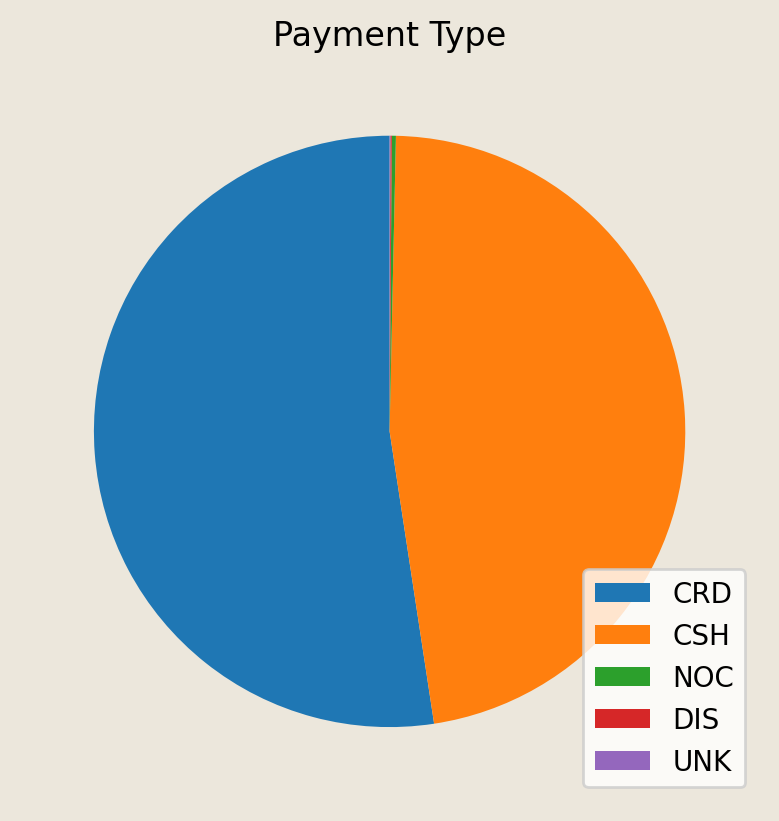

In [14]:
plt.figure(facecolor=BackgroundColor, dpi=200)
plt.pie(tripFare_df["payment_type"].value_counts(), startangle=90)
plt.legend(tripFare_df["payment_type"].value_counts().index)
plt.title("Payment Type")
plt.show()

This time, I will look into the distribution of distances that taxis operate.

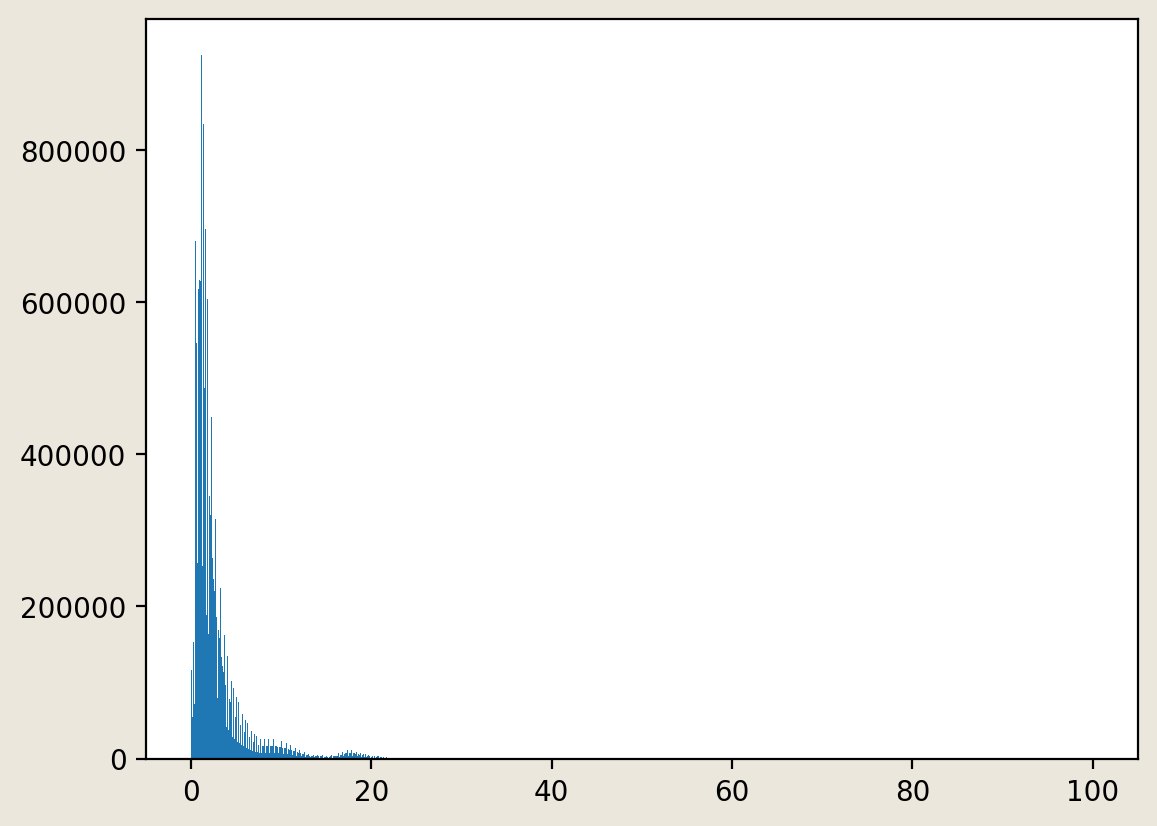

In [15]:
plt.figure(facecolor=BackgroundColor, dpi=200)
plt.hist(tripdata_df["trip_distance"],bins=1000)
plt.show()

It's difficult to check the graph because of the values over 20 (probably miles?). I will integrate the values over 20 into 21 to make it easier to see where the values are concentrated.

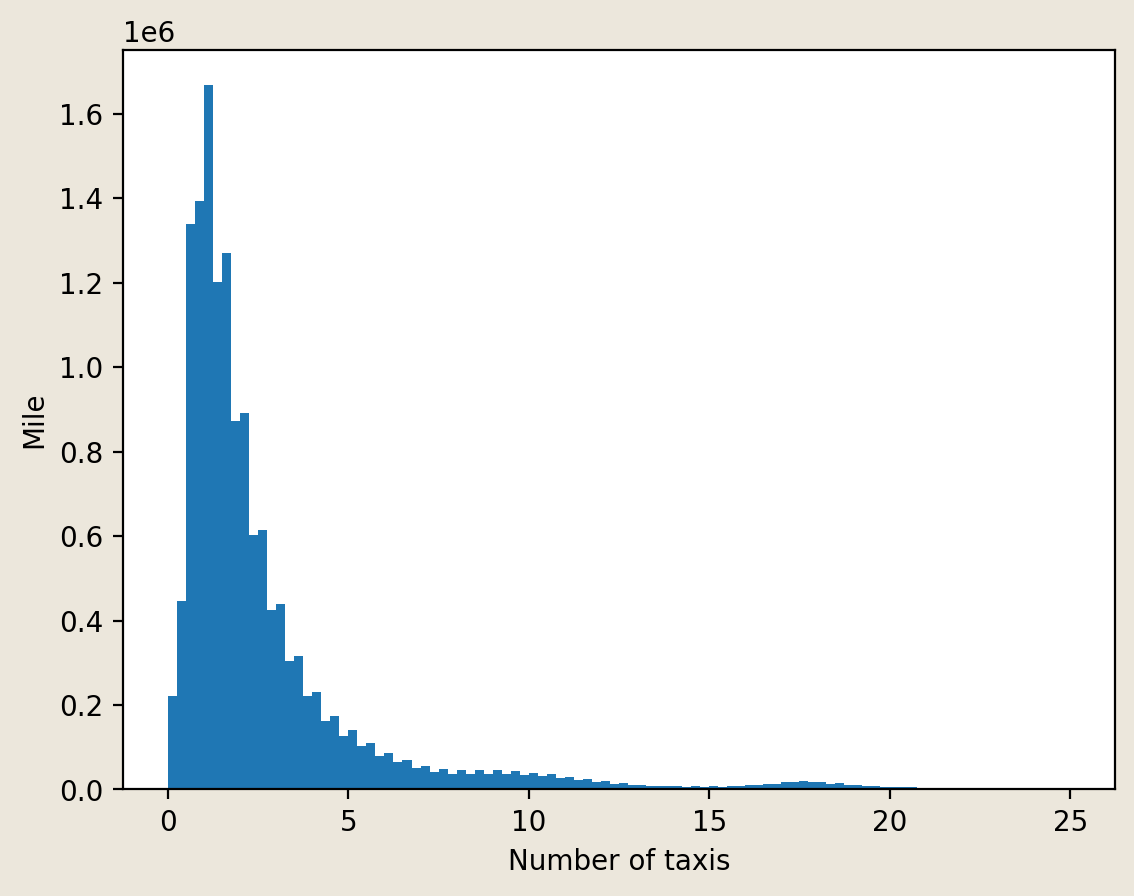

In [16]:
filteredDistance = tripdata_df["trip_distance"]
filteredDistance = filteredDistance[filteredDistance < 25]

plt.figure(facecolor=BackgroundColor, dpi=200)
plt.hist(filteredDistance,bins=100)
plt.xlabel("Number of taxis")
plt.ylabel("Mile")
plt.show()

Looking at it this way, it has a normal distribution shape skewed to the left around 2 miles.

This time, I will analyze the time of day and compare it with the value of (travel time)/(distance).

In [17]:
tripTime_df = pd.DataFrame()
tripTime_df["SpM"] = tripdata_df["trip_time_in_secs"] / tripdata_df["trip_distance"]#Second per Distance
tripTime_df["Pickup_Time"] = tripdata_df["pickup_datetime"].dt.time

tripTime_df.sample(5)

,SpM,Pickup_Time
4557799,382.222222,20:49:43
141220,336.000000,23:11:00
11150002,201.463415,22:19:19
2158183,350.364964,19:11:00
6184216,744.000000,13:33:36


In [18]:
tempTime = tripTime_df[tripTime_df["SpM"] < 10000]['Pickup_Time'].apply(
    lambda t: datetime.combine(datetime.today(), t)
) # Add temporal date to fit with plt x axis datatime
tempSpM = tripTime_df[tripTime_df["SpM"] < 10000]["SpM"]

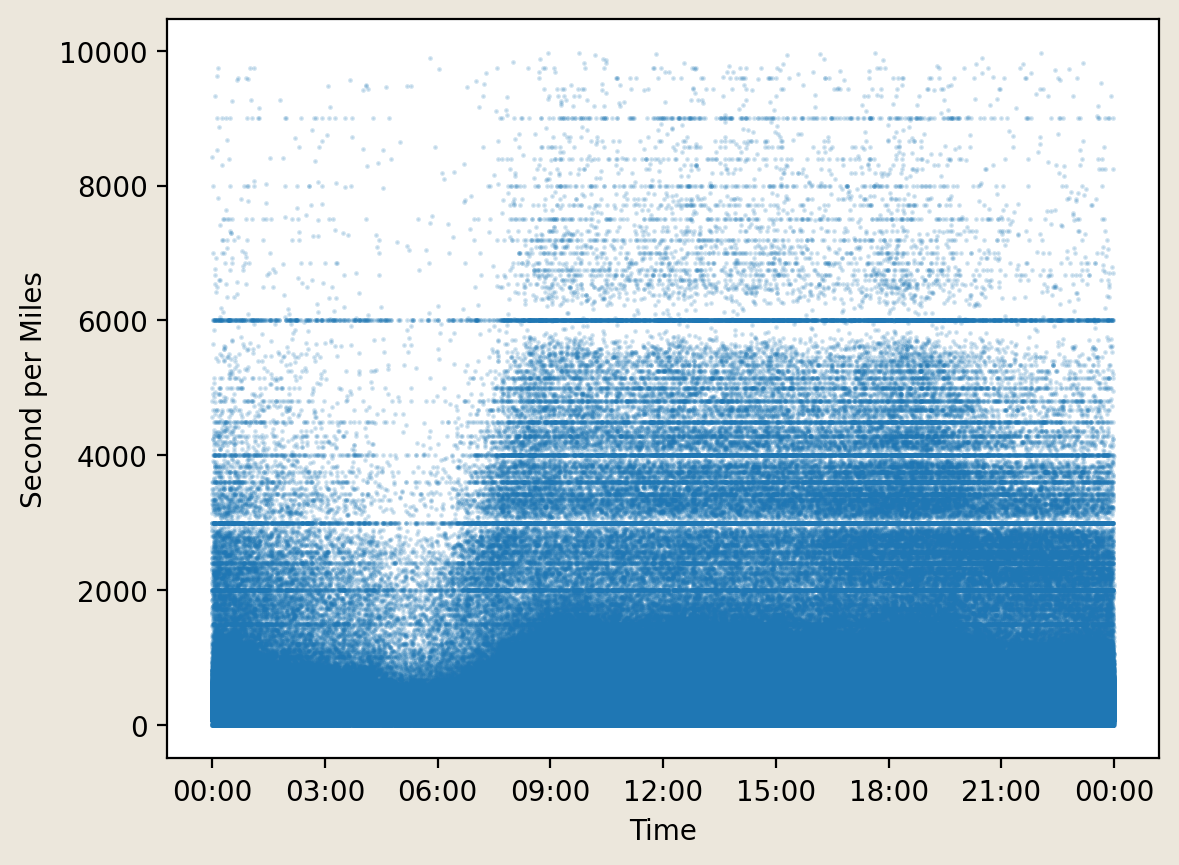

In [19]:
plt.figure(facecolor=BackgroundColor, dpi=200)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.scatter(tempTime, tempSpM, s = 0.5, alpha = 0.2)
plt.xlabel("Time")
plt.ylabel("Second per Miles")
plt.show()

I was a little disappointed because I thought there would be a clear difference. However, I can see that the overall time/distance decreases significantly around 5 a.m.

Now, I will examine the changes in the total earnings of drivers by day of the week.

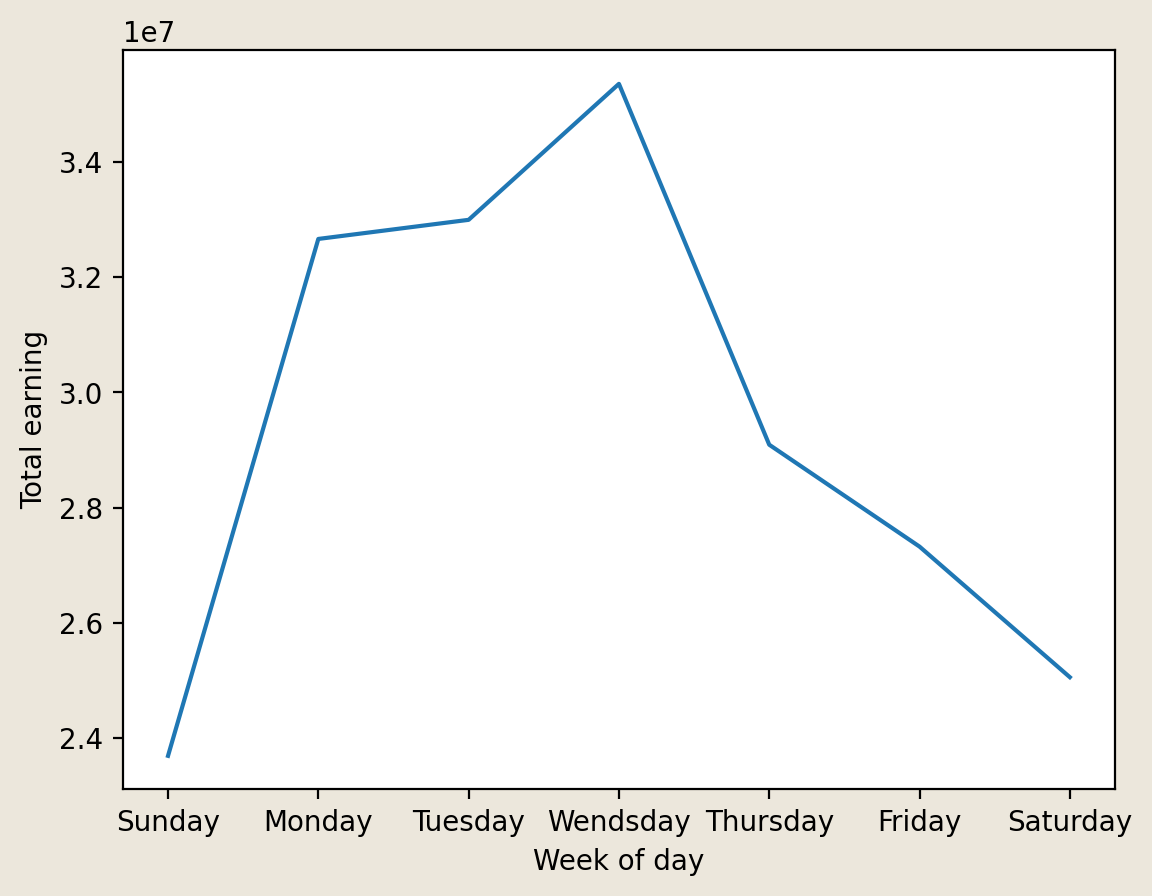

In [20]:
tripFare_df["day_of_week"] = tripFare_df["pickup_datetime"].dt.dayofweek

earningByDay = pd.Series([0.,0.,0.,0.,0.,0.,0.])

for i in range(7):
    earningByDay[i] = tripFare_df[tripFare_df["day_of_week"] == i]["total_amount"].sum()


earningByDay.index = ["Sunday", "Monday", "Tuesday", "Wendsday", "Thursday", "Friday", "Saturday"]
plt.figure(facecolor=BackgroundColor, dpi=200)
plt.xlabel("Week of day")
plt.ylabel("Total earning")
plt.plot(earningByDay.index, earningByDay)
plt.show()

The profit is lower on weekends and higher on weekdays. I thought the income would be higher on weekends because there are a lot of tourists, but it was the opposite.

This time, I will take samples by month and compare the average monthly income.

In [21]:
monthlyFare_df = pd.DataFrame()

for i in range(1,13): #Waning: It will consume a LOT of time
    sample_df = pd.read_csv("trip_fare/trip_fare_"+str(i)+".csv", skipinitialspace=True).sample(100000)
    monthlyFare_df = pd.concat([monthlyFare_df ,sample_df], ignore_index=True)

In [22]:
monthlyFare_df["pickup_datetime"] = pd.to_datetime(monthlyFare_df["pickup_datetime"])
monthlyFare_df["pickup_month"] = monthlyFare_df["pickup_datetime"].dt.month
monthlyFare_df.sample(5)

,medallion,hack_license,vendor_id,pickup_datetime,payment_type,fare_amount,surcharge,mta_tax,tip_amount,tolls_amount,total_amount,pickup_month
271338,D6892CBB7611985DC3EFB6239BB35E74,798292F73B3A3B8310A492C3277E205A,VTS,2013-03-05 16:40:00,CRD,12.5,1.0,0.5,2.70,0.0,16.70,3
618523,67B0EC98DD6BCB83FA5A36106DF74D20,D8B9D865960E245754456E6DFCA149F4,CMT,2013-07-27 21:36:49,CRD,18.5,0.5,0.5,3.90,0.0,23.40,7
631803,C2B9067BB92017120FEF9865217E5E53,628E8E3F91E8CDF9D83DF3E6A9D1F665,CMT,2013-07-31 14:07:19,CRD,11.0,0.0,0.5,2.30,0.0,13.80,7
744093,D740DAC71BFEE9B344EA95FC424EA096,1B61C863CEAB7C65BDC5D2A01DE7E5D2,CMT,2013-08-20 13:08:39,CRD,9.5,0.0,0.5,2.00,0.0,12.00,8
1047410,3C6281F8AA19CBF6FD30411FE2CA8F9F,3AAB94CA53FE93A64811F65690654649,CMT,2013-11-20 22:37:08,CRD,7.5,0.5,0.5,2.12,0.0,10.62,11


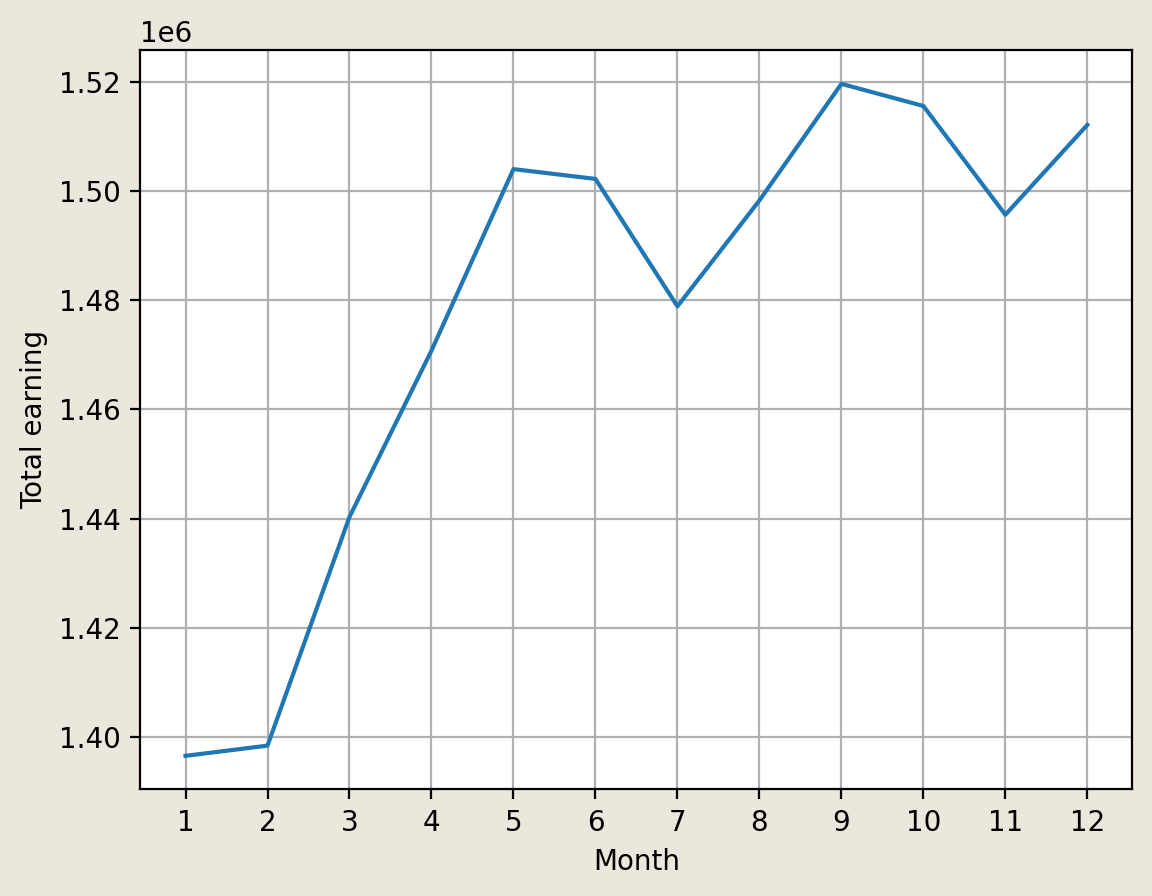

In [23]:
monthlyEarning_df = pd.Series(index = range(1, 12))
for i in range(1, 13):
    monthlyEarning_df[i] = monthlyFare_df[monthlyFare_df["pickup_month"] == i]["total_amount"].sum()

plt.figure(facecolor=BackgroundColor, dpi=200)
plt.plot(monthlyEarning_df.index, monthlyEarning_df)
plt.xticks(range(1,13))
plt.grid()
plt.xlabel("Month")
plt.ylabel("Total earning")
plt.show()

Since the transition from January to May, it showed a steep upward graph, and after that, it is drawing a slight upward graph while plateauing.

This time, let's compare the average daily profit.

In [24]:
dates = monthlyFare_df["pickup_datetime"].dt.date

dates = dates.sort_values()
dates = dates.unique()
dailyEarning_df = pd.DataFrame(index = dates)
dailyEarning_df
for date in dates: # This will take some time
    today_df = monthlyFare_df[monthlyFare_df["pickup_datetime"].dt.date == date]
    dailyEarning_df.loc[date,"Average_Earning"] = today_df["total_amount"].mean()
    dailyEarning_df.loc[date,"Num_Of_Rides"] = today_df["total_amount"].size
    dailyEarning_df.loc[date,"Total_Earning"] = today_df["total_amount"].sum()

dailyEarning_df

,Average_Earning,Num_Of_Rides,Total_Earning
2013-01-01,15.208593,2858.0,43466.16
2013-01-02,14.345106,2691.0,38602.68
2013-01-03,13.837794,3042.0,42094.57
2013-01-04,13.555964,3238.0,43894.21
2013-01-05,13.400481,3221.0,43162.95
...,...,...,...
2013-12-27,14.602539,2824.0,41237.57
2013-12-28,14.446034,2852.0,41200.09
2013-12-29,14.418708,2987.0,43068.68
2013-12-30,14.933465,2851.0,42575.31


In [25]:
pd.date_range(start='2012-1-1', freq="MS", periods=12)

DatetimeIndex(['2012-01-01', '2012-02-01', '2012-03-01', '2012-04-01',
               '2012-05-01', '2012-06-01', '2012-07-01', '2012-08-01',
               '2012-09-01', '2012-10-01', '2012-11-01', '2012-12-01'],
              dtype='datetime64[ns]', freq='MS')

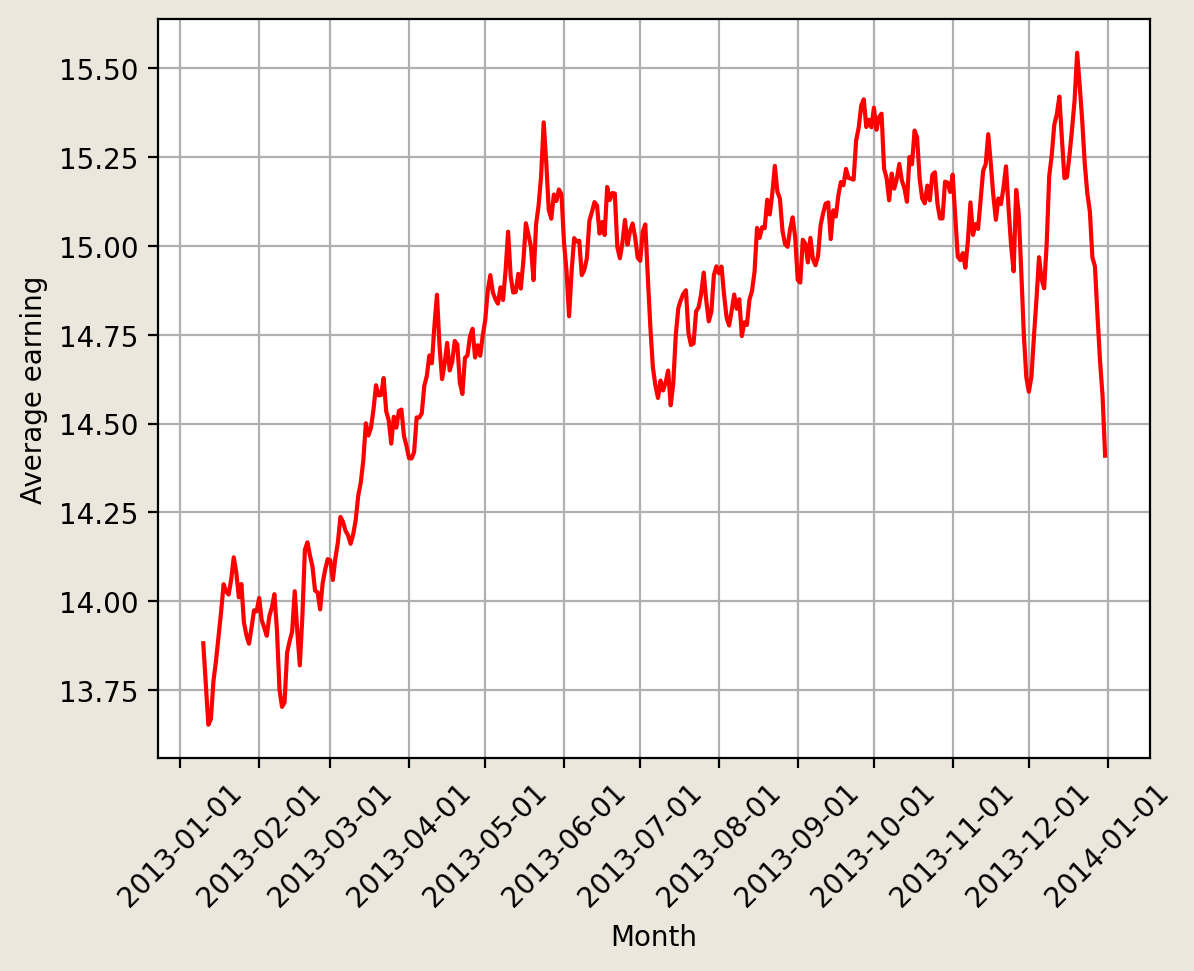

In [26]:
plt.figure(facecolor=BackgroundColor, dpi=200)
# plt.plot(dailyEarning_mean_df.index, dailyEarning_mean_df)
dailyEarning_df["Average_Earning"].rolling(10).mean().plot(color="r")
plt.grid()
plt.xticks(pd.date_range(start='2013-1-1', end="2014-1-1", freq="MS"),rotation = 45)
plt.xlabel("Month")
plt.ylabel("Average earning")
plt.show()

The shape of the graph is similar to the monthly total earning graph.

This got me curious, so I also compared the number of times a taxi operated in a day.

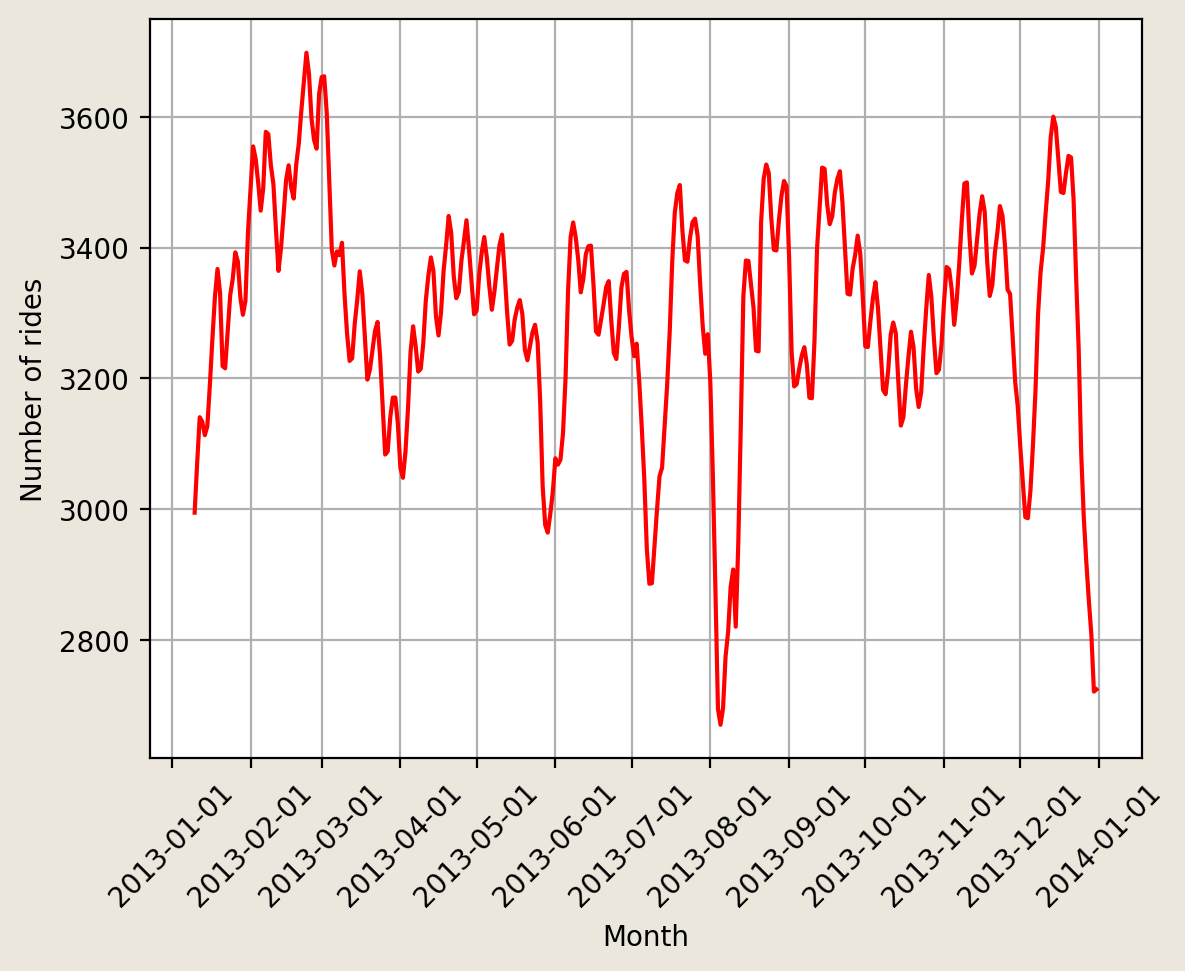

In [27]:
plt.figure(facecolor=BackgroundColor, dpi=200)
# plt.plot(dailyEarning_mean_df.index, dailyEarning_mean_df)
dailyEarning_df["Num_Of_Rides"].rolling(10).mean().plot(color="r")
plt.grid()
plt.xticks(pd.date_range(start='2013-1-1', end="2014-1-1", freq="MS"),rotation = 45)
plt.xlabel("Month")
plt.ylabel("Number of rides")
plt.show()


Hmm, the graph is more consistent than I expected. This time, I'll create a graph of the total daily revenue instead of a graph combined by month.

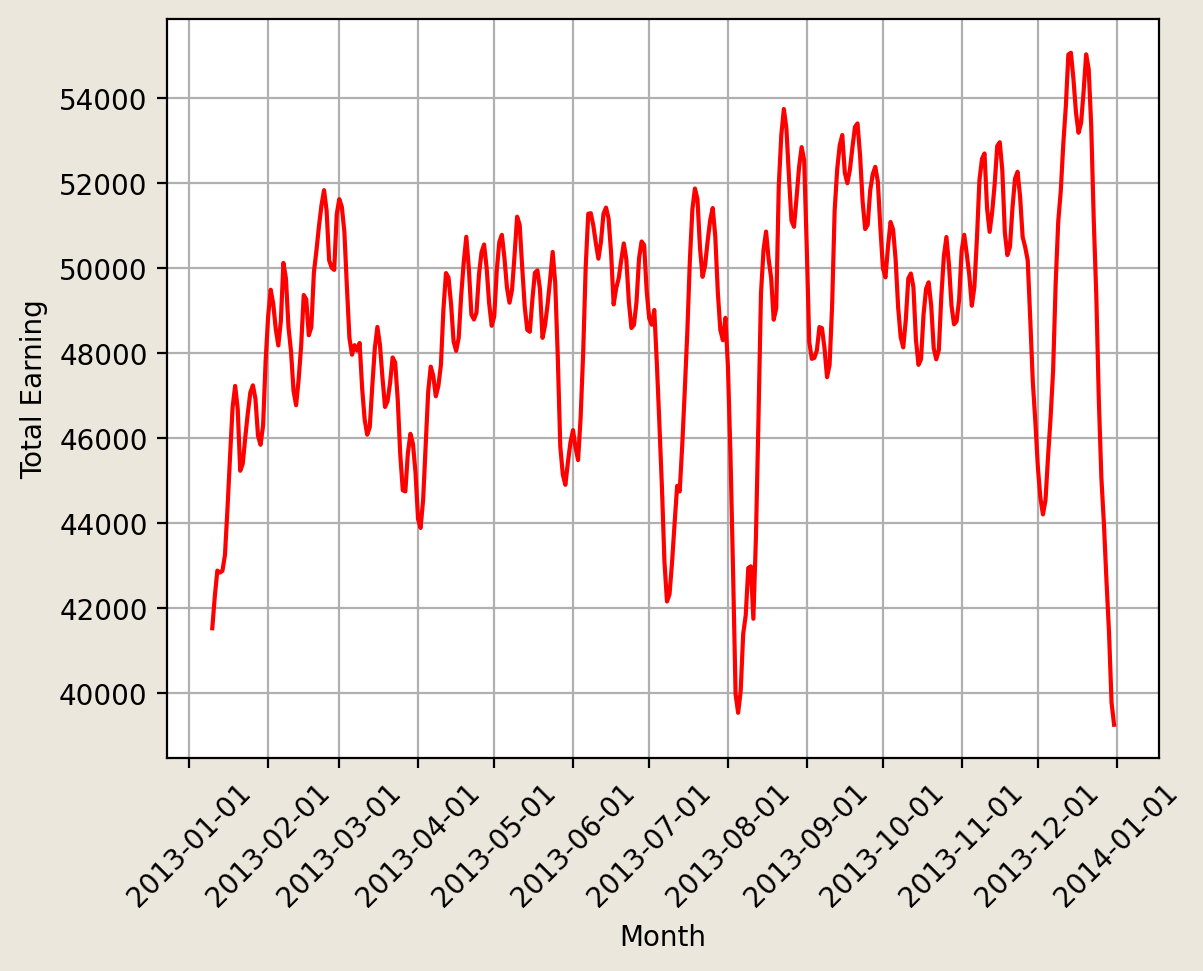

In [28]:
plt.figure(facecolor=BackgroundColor, dpi=200)
# plt.plot(dailyEarning_mean_df.index, dailyEarning_mean_df)
dailyEarning_df["Total_Earning"].rolling(10).mean().plot(color="r")
plt.grid()
plt.xticks(pd.date_range(start='2013-1-1', end="2014-1-1", freq="MS"),rotation = 45)
plt.xlabel("Month")
plt.ylabel("Total Earning")
plt.show()

Looking at it this way, it's very different from the graph I used to see monthly. Rather, it seems similar to the number of times a taxi operated. So, I created a correlation table and compared them.

In [29]:
colors = ["#E44067", BackgroundColor, "#322F2A"]
custom_cmap = LinearSegmentedColormap.from_list("CustomCmap", colors)
dailyEarning_df.select_dtypes(include=['number']).corr().style.background_gradient(cmap=custom_cmap, vmin=-1, vmax=1)

,Average_Earning,Num_Of_Rides,Total_Earning
Average_Earning,1.000000,0.026117,0.398944
Num_Of_Rides,0.026117,1.000000,0.926052
Total_Earning,0.398944,0.926052,1.000000


To make an intuitive comparison with the graph, I compared the three graphs using min-max normalization.

In [30]:
Normalized_df = pd.DataFrame()
Normalized_df["Total_Earning"] = (dailyEarning_df["Total_Earning"] - dailyEarning_df["Total_Earning"].min()) / (dailyEarning_df["Total_Earning"].max() - dailyEarning_df["Total_Earning"].min())
Normalized_df["Average_Earning"] = (dailyEarning_df["Average_Earning"] - dailyEarning_df["Average_Earning"].min()) / (dailyEarning_df["Average_Earning"].max() - dailyEarning_df["Average_Earning"].min())
Normalized_df["Num_Of_Rides"] = (dailyEarning_df["Num_Of_Rides"] - dailyEarning_df["Num_Of_Rides"].min()) / (dailyEarning_df["Num_Of_Rides"].max() - dailyEarning_df["Num_Of_Rides"].min())

Normalized_df

,Total_Earning,Average_Earning,Num_Of_Rides
2013-01-01,0.498515,0.704216,0.486662
2013-01-02,0.373670,0.484139,0.423018
2013-01-03,0.463307,0.354840,0.556784
2013-01-04,0.509503,0.283010,0.631479
2013-01-05,0.490732,0.243382,0.625000
...,...,...,...
2013-12-27,0.441307,0.549751,0.473704
2013-12-28,0.440345,0.509862,0.484375
2013-12-29,0.488312,0.502898,0.535823
2013-12-30,0.475647,0.634094,0.483994


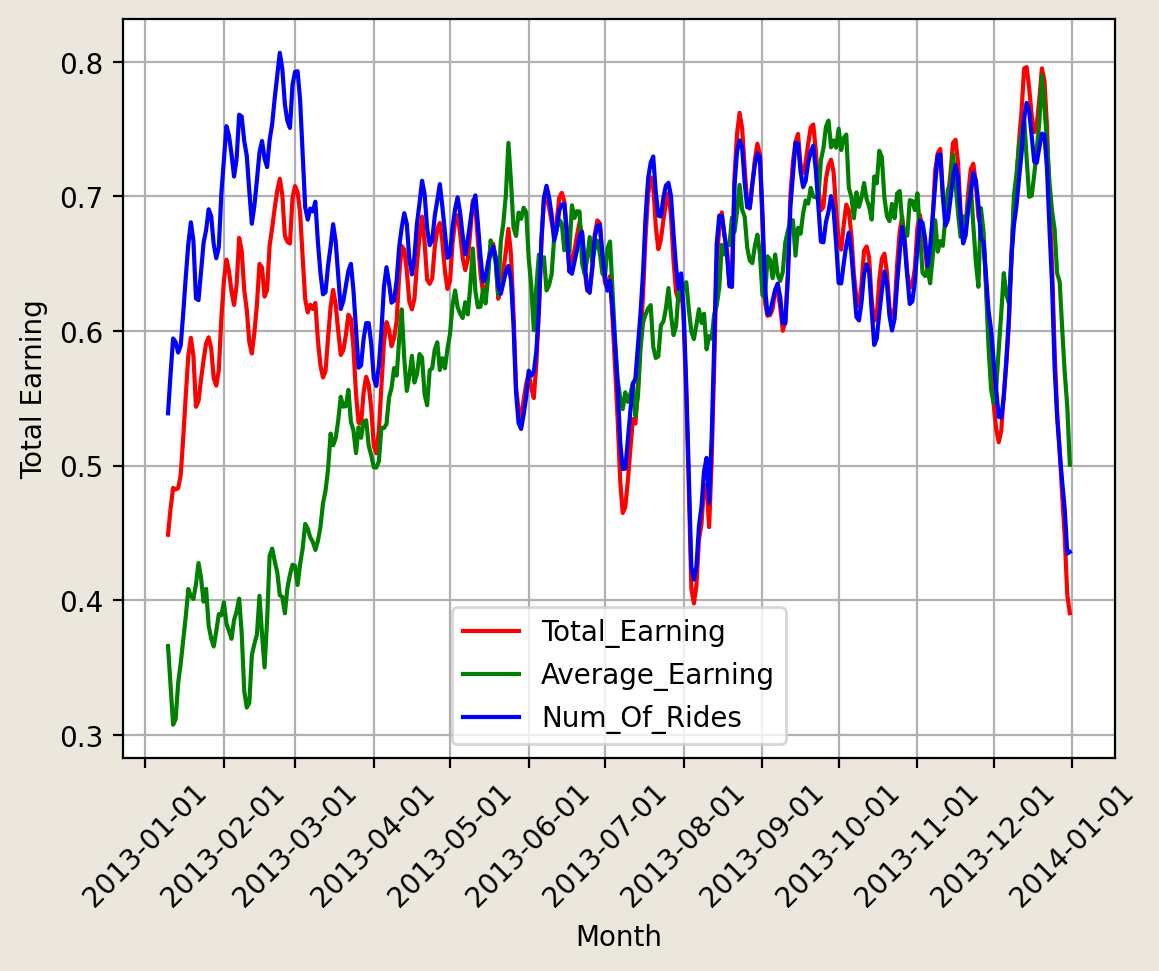

In [31]:
plt.figure(facecolor=BackgroundColor, dpi=200)
# plt.plot(dailyEarning_mean_df.index, dailyEarning_mean_df)
Normalized_df["Total_Earning"].rolling(10).mean().plot(color="r")
Normalized_df["Average_Earning"].rolling(10).mean().plot(color="g")
Normalized_df["Num_Of_Rides"].rolling(10).mean().plot(color="b")
plt.grid()
plt.xticks(pd.date_range(start='2013-1-1', end="2014-1-1", freq="MS"),rotation = 45)
plt.xlabel("Month")
plt.ylabel("Total Earning")
plt.legend(["Total_Earning", "Average_Earning", "Num_Of_Rides"])
plt.show()

Looking at it this way, we can see that the total revenue is more related to the number of trips than the revenue per trip.

## Conclusion

Analyzing this data, we found that even in 2013, people preferred card payments over cash, taxis usually traveled within about 2 miles, traffic decreased around 5 a.m., revenue was generally lower on weekends, and the number of trips had a stronger impact on total revenue than the average fare per trip.